# 02 — V2 Causal Training, Sample Weighting & Blind Evaluation

Reference pipeline based on the stable **V2 architecture**:
- **Zero-Leakage Chronological Split:** Train (`< 2026-06-01`), Validation (`2026-06`), Blind Holdout Test (`>= 2026-07-01`).
- **Causal Site Profiling:** `site_cf_mean`, `site_cf_std`, and `site_load_mean` fitted strictly on Train with global fallbacks.
- **Physical Regime Sample Weighting:** Prioritizes battery-saturation curtailment (`2.5x`), peak irradiance (`1.5x`), and low-irradiance twilight (`1.3x`).
- **Dual LightGBM Models:** Solar Capacity Factor (`capacity_factor` → kW reconstruction) + Telecom Load Demand (`load_power_kw`).

In [1]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from microgrid_ml.config import load_config
from microgrid_ml.models.train_v2 import train_v2_pipeline
from microgrid_ml.visualization.plots import (
    plot_feature_importance,
    plot_solar_blind_test_series,
)

cfg = load_config(repo_root=REPO_ROOT)
artifacts = train_v2_pipeline(cfg)

print("=== BLIND TEST METRICS (SYNTHETIC SAMPLE) ===")
print(f"Solar V2 -> R2: {artifacts.solar_metrics.r2:.4f} | nRMSE: {artifacts.solar_metrics.nrmse_pu:.4f} | "
      f"RMSE: {artifacts.solar_metrics.rmse_kw:.3f} kW | MAE: {artifacts.solar_metrics.mae_kw:.3f} kW | "
      f"WAPE: {artifacts.solar_metrics.wape_pct:.2f}%")
print(f"Load  V2 -> R2: {artifacts.load_metrics.r2:.4f} | RMSE: {artifacts.load_metrics.rmse_kw:.3f} kW | "
      f"WAPE: {artifacts.load_metrics.wape_pct:.2f}%")

=== BLIND TEST METRICS (SYNTHETIC SAMPLE) ===
Solar V2 -> R2: 0.8890 | nRMSE: 0.0746 | RMSE: 1.711 kW | MAE: 0.794 kW | WAPE: 12.79%
Load  V2 -> R2: 0.9908 | RMSE: 0.070 kW | WAPE: 3.77%


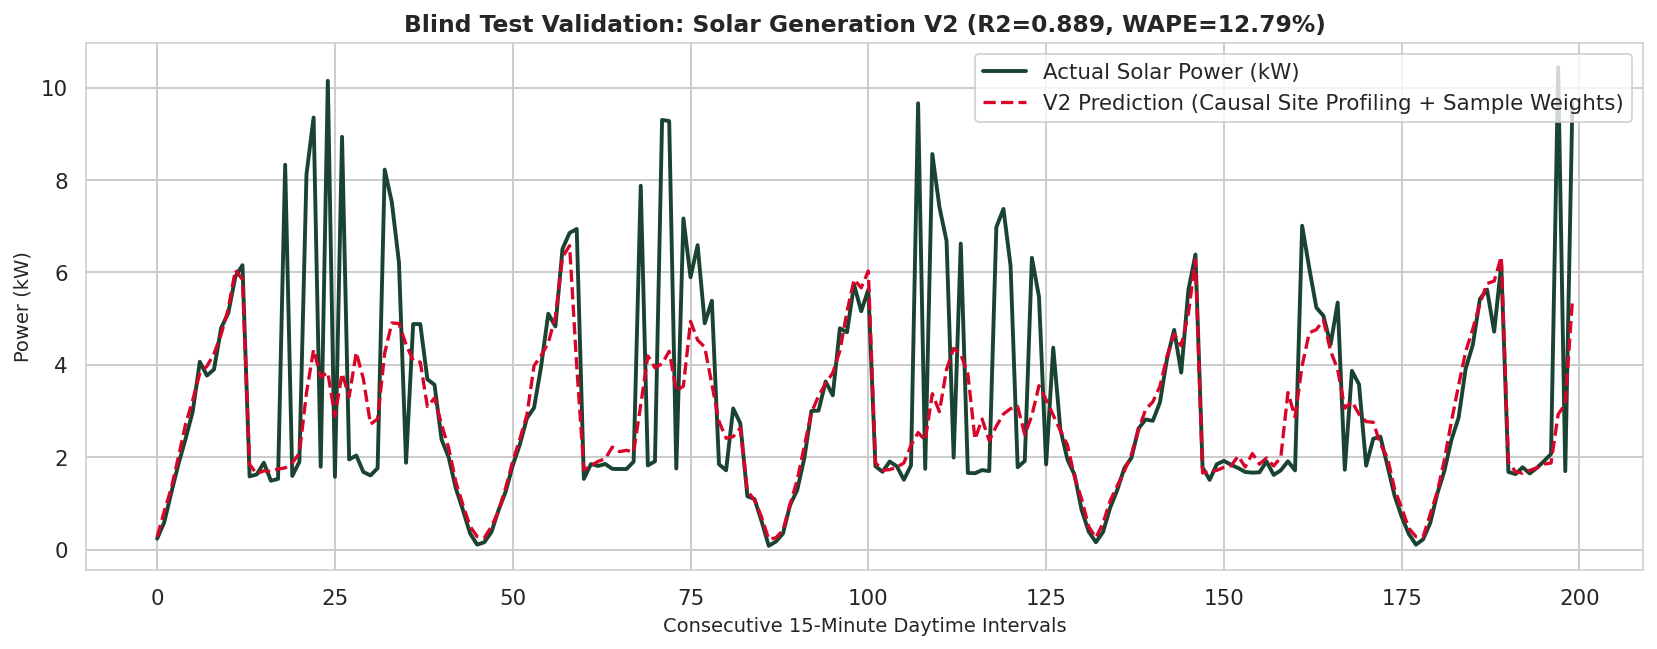

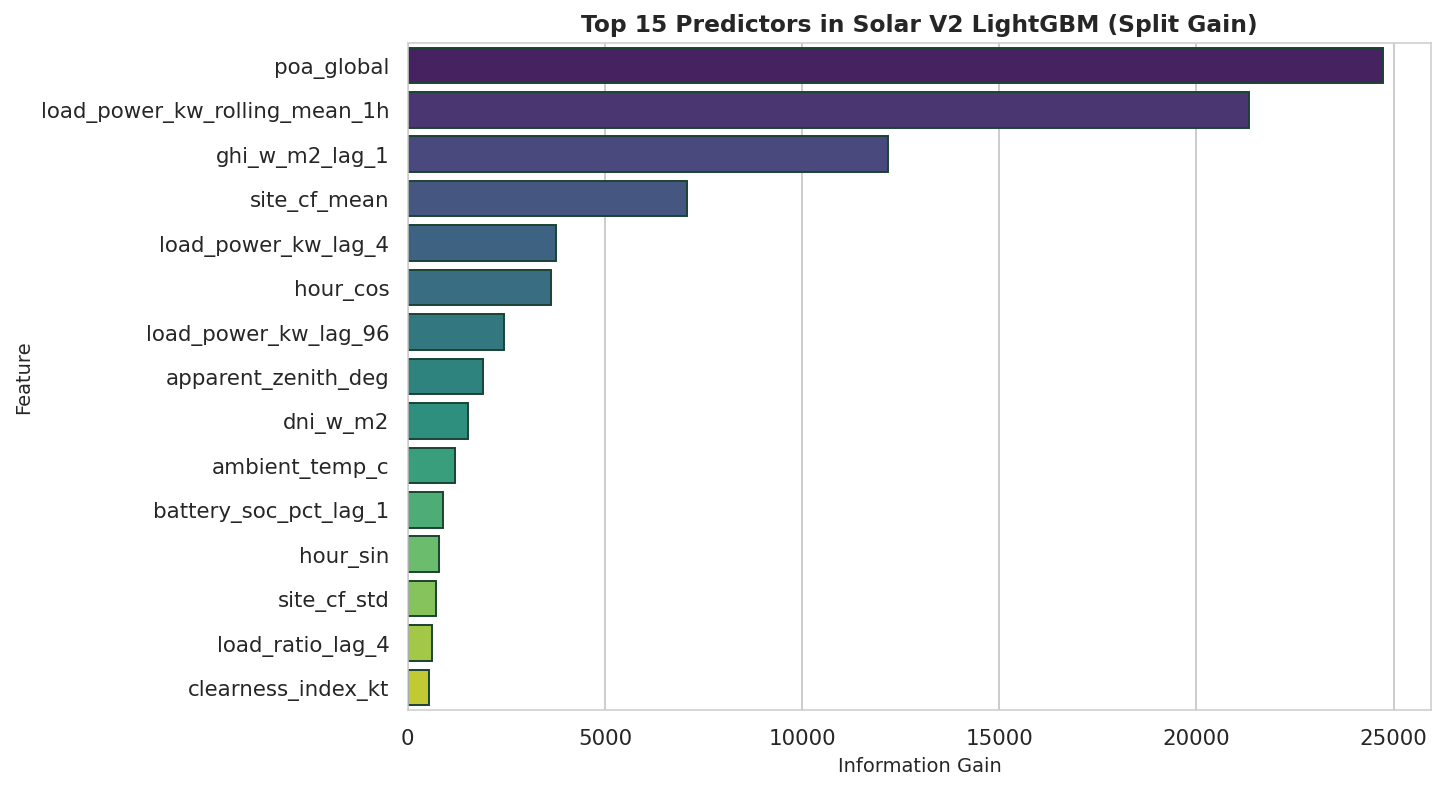

In [2]:
from IPython.display import Image, display

series_fig = plot_solar_blind_test_series(artifacts, cfg.figures_dir / "solar_blind_test_series.png")
imp_fig = plot_feature_importance(artifacts, cfg.figures_dir / "feature_importance_solar_v2.png")

display(Image(filename=str(series_fig)))
display(Image(filename=str(imp_fig)))